# Démonstration : classification et localisation satellite/debris

Six images de validation (trois satellites et trois débris) sont classées et localisées. La boîte prédite est colorée selon son IoU avec la vérité terrain ; cette dernière est tracée en blanc pointillé.

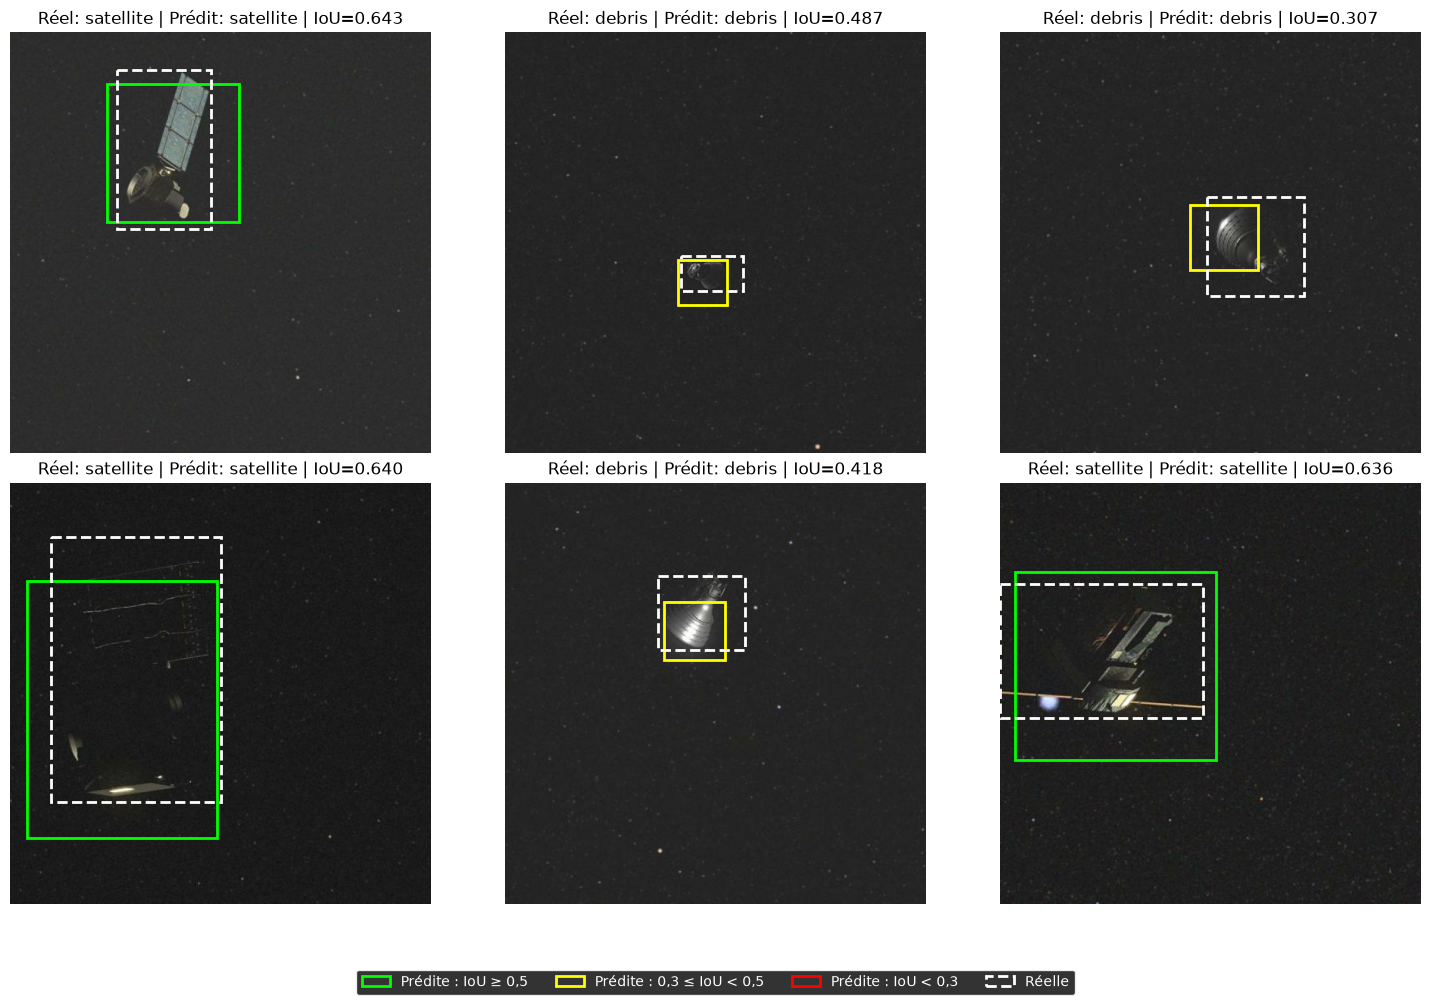

,image,classe réelle,classe prédite,probabilité debris,IoU,"bbox normalisée [ymin, xmin, ymax, xmax]"
0,img040921_jpg.rf.92e70ec73fae81f1a60e6bbcc0c5a...,satellite,satellite,0.000000,0.6430,"(0.123, 0.2287, 0.449, 0.5426)"
1,img023320_jpg.rf.cd4c30b40ca6876524030bc8faf49...,debris,debris,0.999893,0.4871,"(0.5397, 0.4097, 0.6472, 0.5273)"
2,img022155_jpg.rf.37e57644fddefec749e6ac7b2e771...,debris,debris,0.999997,0.3071,"(0.4083, 0.4502, 0.5628, 0.612)"
3,img061446_jpg.rf.d7cdaea5e49a40a48c790a48bb46d...,satellite,satellite,0.000000,0.6403,"(0.2336, 0.0387, 0.842, 0.4907)"
4,img021951_jpg.rf.b32dfa41312e0b13e543782b93544...,debris,debris,0.999988,0.4185,"(0.2821, 0.3762, 0.419, 0.5214)"
5,img091229_jpg.rf.0caa6b510e3246604aadeb9d469c5...,satellite,satellite,0.000000,0.6361,"(0.2123, 0.0353, 0.658, 0.5114)"


In [2]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import tensorflow as tf
import yaml
from IPython.display import display

working_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (working_dir, *working_dir.parents)
     if (path / "data/valid/images").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Impossible de trouver data/valid/images depuis le dossier courant.")

validation_dir = project_root / "data/valid/images"
image_paths = sorted(validation_dir.glob("*.jpg"))
with (project_root / "data/data.yaml").open(encoding="utf-8") as file:
    class_names = yaml.safe_load(file)["names"]

satellite_candidates = []
debris_candidates = []
labels_dir = project_root / "data/valid/labels"
for image_path in image_paths:
    label_path = labels_dir / f"{image_path.stem}.txt"
    if not label_path.is_file():
        continue
    label_lines = [line.split() for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    if not label_lines:
        continue
    class_id = int(label_lines[0][0])
    x_center, y_center, box_width, box_height = map(float, label_lines[0][1:])
    class_name = class_names[class_id]
    binary_class_name = "debris" if class_name == "debris" else "satellite"
    true_box = (
        max(0.0, y_center - box_height / 2),
        max(0.0, x_center - box_width / 2),
        min(1.0, y_center + box_height / 2),
        min(1.0, x_center + box_width / 2),
    )
    candidate = (image_path, binary_class_name, true_box)
    if binary_class_name == "debris":
        debris_candidates.append(candidate)
    else:
        satellite_candidates.append(candidate)

if len(satellite_candidates) < 3 or len(debris_candidates) < 3:
    raise ValueError(
        f"Il faut au moins 3 images de chaque classe avec annotations. "
        f"Trouve : {len(satellite_candidates)} satellites et {len(debris_candidates)} debris."
    )
selected_images = random.sample(satellite_candidates, 3) + random.sample(debris_candidates, 3)
random.shuffle(selected_images)

# Le même modèle multitâche produit la classe et la boîte.
detector_path = project_root / "src/models/BBOX/satellite_debris_bbox_lronplateau.keras"
if not detector_path.is_file():
    raise FileNotFoundError(f"Modèle introuvable : {detector_path}")
detector = tf.keras.models.load_model(detector_path, compile=False)

results = []
figure, axes = plt.subplots(2, 3, figsize=(15, 10))
for (image_path, true_class, true_box), axis in zip(selected_images, axes.flat):
    original = tf.io.decode_jpeg(tf.io.read_file(str(image_path)), channels=3)
    resized = tf.image.resize(original, [224, 224])
    model_input = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.cast(resized, tf.float32)
    )
    batch = tf.expand_dims(model_input, 0)
    predictions = detector.predict(batch, verbose=0)
    probability_debris = float(predictions["class_output"][0, 0])
    predicted_class = "debris" if probability_debris >= 0.5 else "satellite"
    predicted_box = predictions["bbox_output"][0].tolist()
    ymin, xmin, ymax, xmax = predicted_box
    image_height, image_width = tf.shape(original)[:2].numpy()

    true_ymin, true_xmin, true_ymax, true_xmax = true_box
    intersection_height = max(0.0, min(ymax, true_ymax) - max(ymin, true_ymin))
    intersection_width = max(0.0, min(xmax, true_xmax) - max(xmin, true_xmin))
    intersection = intersection_height * intersection_width
    predicted_area = max(0.0, ymax - ymin) * max(0.0, xmax - xmin)
    true_area = max(0.0, true_ymax - true_ymin) * max(0.0, true_xmax - true_xmin)
    union = predicted_area + true_area - intersection
    iou = intersection / union if union > 0 else 0.0
    bbox_color = "lime" if iou >= 0.5 else "yellow" if iou >= 0.3 else "red"

    results.append({
        "image": image_path.name,
        "classe réelle": true_class,
        "classe prédite": predicted_class,
        "probabilité debris": round(probability_debris, 6),
        "IoU": round(iou, 4),
        "bbox normalisée [ymin, xmin, ymax, xmax]": tuple(
            round(value, 4) for value in (ymin, xmin, ymax, xmax)
        ),
    })

    axis.imshow(original.numpy())
    axis.add_patch(patches.Rectangle(
        (xmin * image_width, ymin * image_height),
        (xmax - xmin) * image_width,
        (ymax - ymin) * image_height,
        linewidth=2,
        edgecolor=bbox_color,
        facecolor="none",
    ))
    axis.add_patch(patches.Rectangle(
        (true_xmin * image_width, true_ymin * image_height),
        (true_xmax - true_xmin) * image_width,
        (true_ymax - true_ymin) * image_height,
        linewidth=2,
        edgecolor="white",
        facecolor="none",
        linestyle="--",
    ))
    axis.set_title(
        f"Réel: {true_class} | Prédit: {predicted_class} | IoU={iou:.3f}",
        color="red" if predicted_class != true_class else "black",
    )
    axis.axis("off")

legend = figure.legend(
    handles=[
        patches.Patch(facecolor="none", edgecolor="lime", linewidth=2, label="Prédite : IoU ≥ 0,5"),
        patches.Patch(facecolor="none", edgecolor="yellow", linewidth=2, label="Prédite : 0,3 ≤ IoU < 0,5"),
        patches.Patch(facecolor="none", edgecolor="red", linewidth=2, label="Prédite : IoU < 0,3"),
        patches.Patch(facecolor="none", edgecolor="white", linestyle="--", linewidth=2, label="Réelle"),
    ],
    loc="lower center",
    ncol=4,
    frameon=True,
    facecolor="black",
    edgecolor="white",
)
plt.setp(legend.get_texts(), color="white")
figure.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
display(pd.DataFrame(results))
